# Task 21: Manual Outlier Detection

## Objective
To identify outliers in numerical features using the IQR and Z-score
methods. Quartiles, mean, and standard deviation are calculated manually,
and outliers are visualized using a custom plotting approach.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [3]:
numerical_df = df.select_dtypes(include=["number"])

# Exclude target because it is a class label, not a continuous measurement
feature_columns = [
    col for col in numerical_df.columns
    if col != "target"
]

print("Numerical features:", feature_columns)

Numerical features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [4]:
def manual_mean(values):
    values = [float(v) for v in values if pd.notna(v)]

    if len(values) == 0:
        return 0

    return sum(values) / len(values)


def manual_std(values):
    values = [float(v) for v in values if pd.notna(v)]

    if len(values) < 2:
        return 0

    mean_value = manual_mean(values)
    variance = sum((v - mean_value) ** 2 for v in values) / len(values)

    return variance ** 0.5


def manual_percentile(values, percentile):
    values = sorted(
        float(v) for v in values if pd.notna(v)
    )

    if len(values) == 0:
        return 0

    position = (len(values) - 1) * percentile / 100
    lower_index = int(position)
    upper_index = min(lower_index + 1, len(values) - 1)

    fraction = position - lower_index

    return (
        values[lower_index] * (1 - fraction)
        + values[upper_index] * fraction
    )


In [5]:
outlier_results = {}

for col in feature_columns:
    values = [
        float(v) for v in df[col]
        if pd.notna(v)
    ]

    q1 = manual_percentile(values, 25)
    q3 = manual_percentile(values, 75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mean_value = manual_mean(values)
    std_value = manual_std(values)

    iqr_outliers = []
    zscore_outliers = []

    for index, value in enumerate(df[col]):
        if pd.isna(value):
            continue

        value = float(value)

        if value < lower_bound or value > upper_bound:
            iqr_outliers.append((index, value))

        if std_value > 0:
            z_score = (value - mean_value) / std_value

            if abs(z_score) > 3:
                zscore_outliers.append((index, value, z_score))

    outlier_results[col] = {
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "mean": mean_value,
        "std": std_value,
        "iqr_outliers": iqr_outliers,
        "zscore_outliers": zscore_outliers
    }

    print("\nFeature:", col)
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("IQR:", round(iqr, 2))
    print("IQR bounds:", round(lower_bound, 2), "to", round(upper_bound, 2))
    print("Mean:", round(mean_value, 2))
    print("Standard deviation:", round(std_value, 2))
    print("IQR outlier count:", len(iqr_outliers))
    print("Z-score outlier count:", len(zscore_outliers))


Feature: age
Q1: 48.0
Q3: 61.0
IQR: 13.0
IQR bounds: 28.5 to 80.5
Mean: 54.43
Standard deviation: 9.07
IQR outlier count: 0
Z-score outlier count: 0

Feature: sex
Q1: 0.0
Q3: 1.0
IQR: 1.0
IQR bounds: -1.5 to 2.5
Mean: 0.7
Standard deviation: 0.46
IQR outlier count: 0
Z-score outlier count: 0

Feature: cp
Q1: 0.0
Q3: 2.0
IQR: 2.0
IQR bounds: -3.0 to 5.0
Mean: 0.94
Standard deviation: 1.03
IQR outlier count: 0
Z-score outlier count: 0

Feature: trestbps
Q1: 120.0
Q3: 140.0
IQR: 20.0
IQR bounds: 90.0 to 170.0
Mean: 131.61
Standard deviation: 17.51
IQR outlier count: 30
Z-score outlier count: 7

Feature: chol
Q1: 211.0
Q3: 275.0
IQR: 64.0
IQR bounds: 115.0 to 371.0
Mean: 246.0
Standard deviation: 51.57
IQR outlier count: 16
Z-score outlier count: 13

Feature: fbs
Q1: 0.0
Q3: 0.0
IQR: 0.0
IQR bounds: 0.0 to 0.0
Mean: 0.15
Standard deviation: 0.36
IQR outlier count: 153
Z-score outlier count: 0

Feature: restecg
Q1: 0.0
Q3: 1.0
IQR: 1.0
IQR bounds: -1.5 to 2.5
Mean: 0.53
Standard deviation:

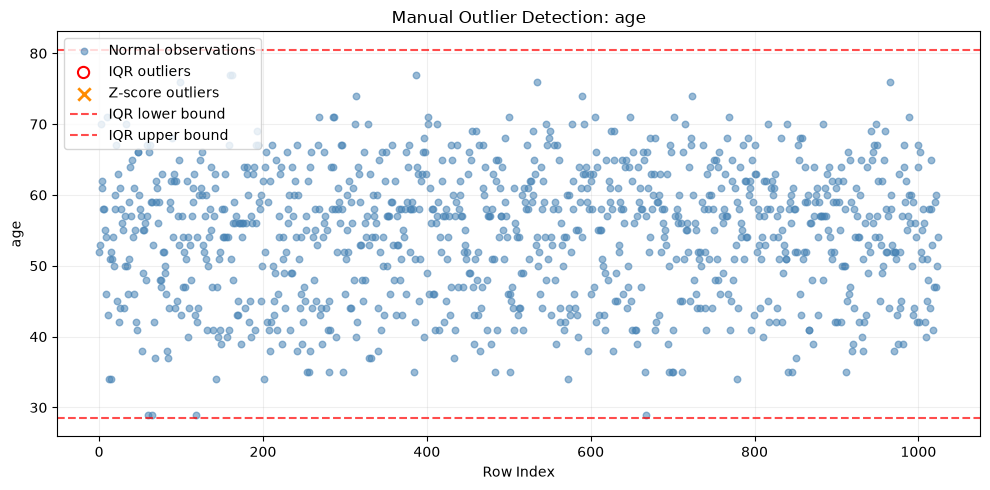

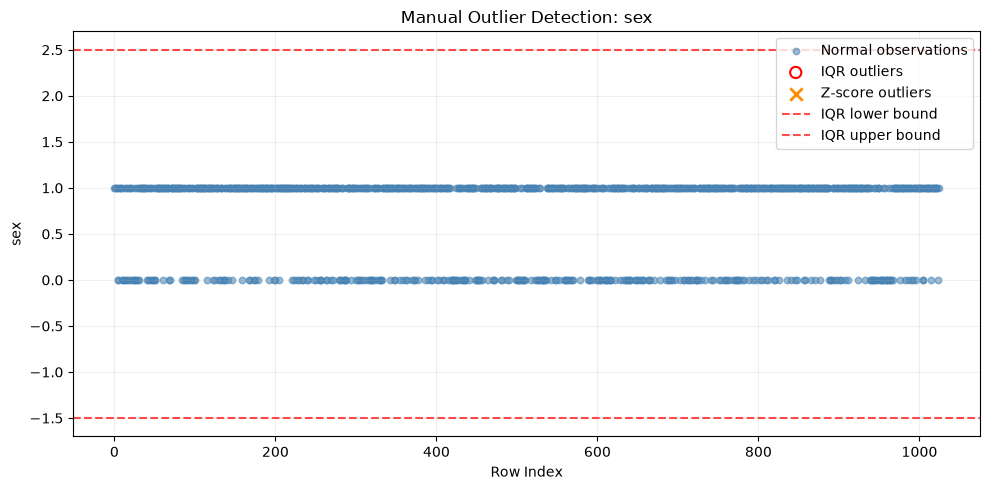

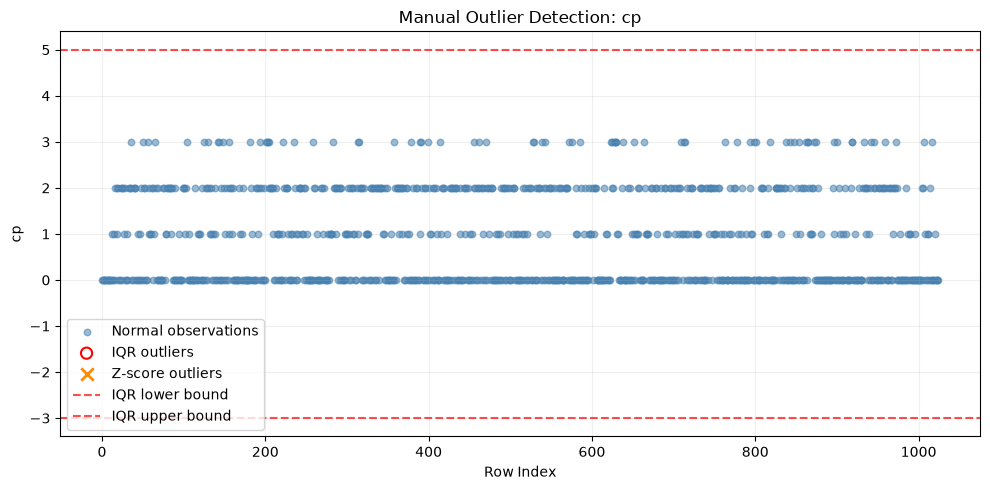

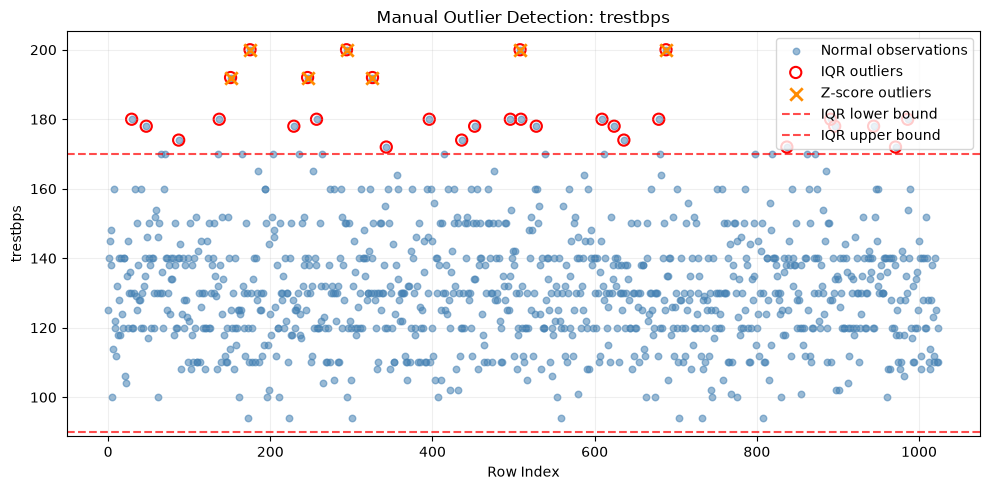

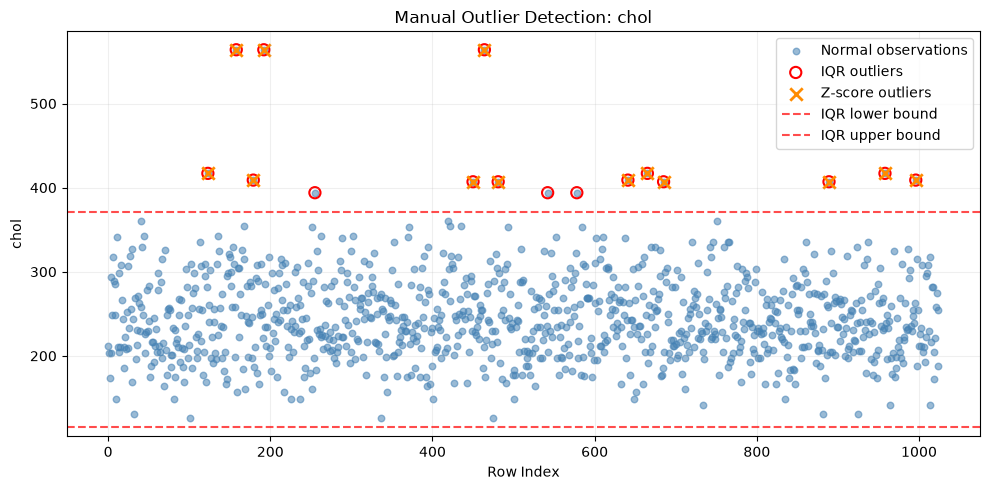

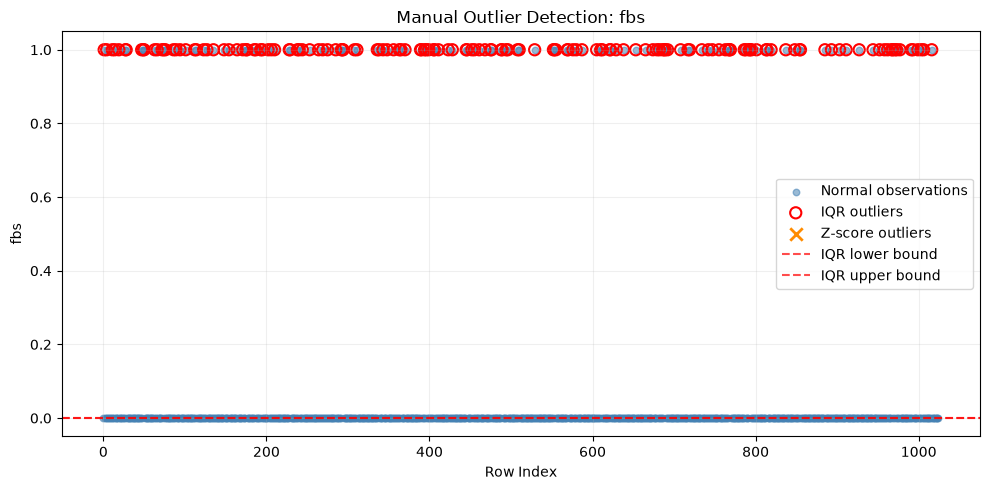

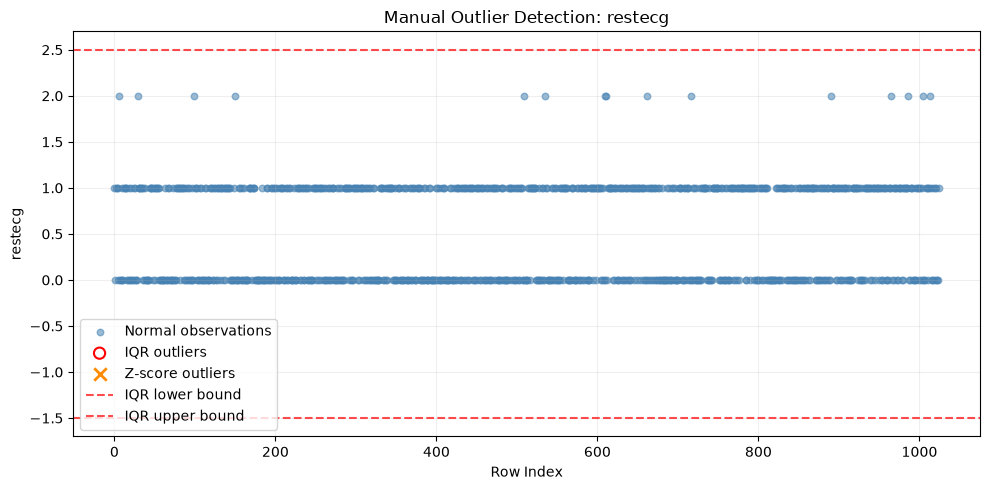

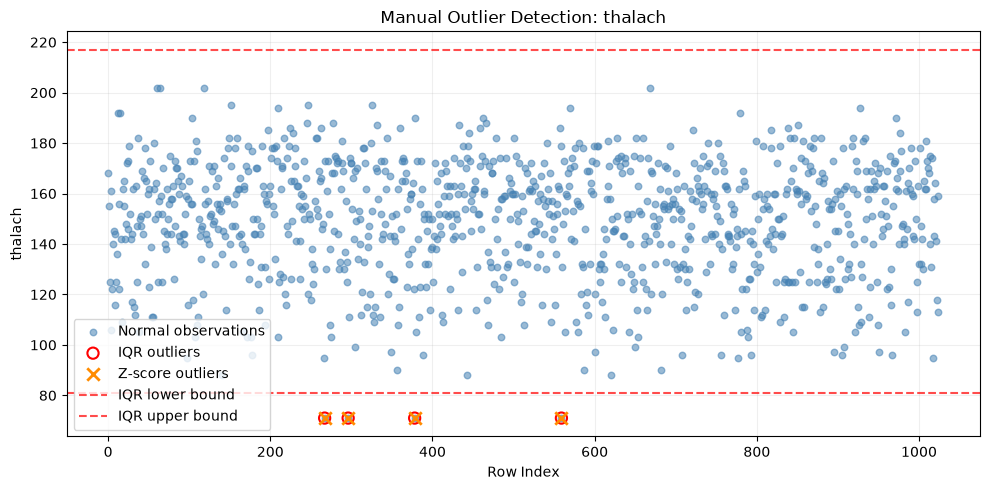

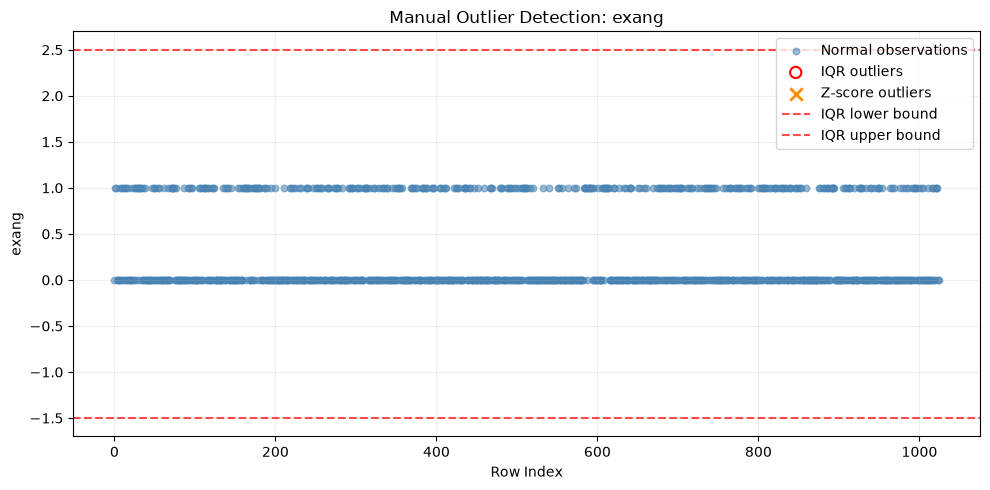

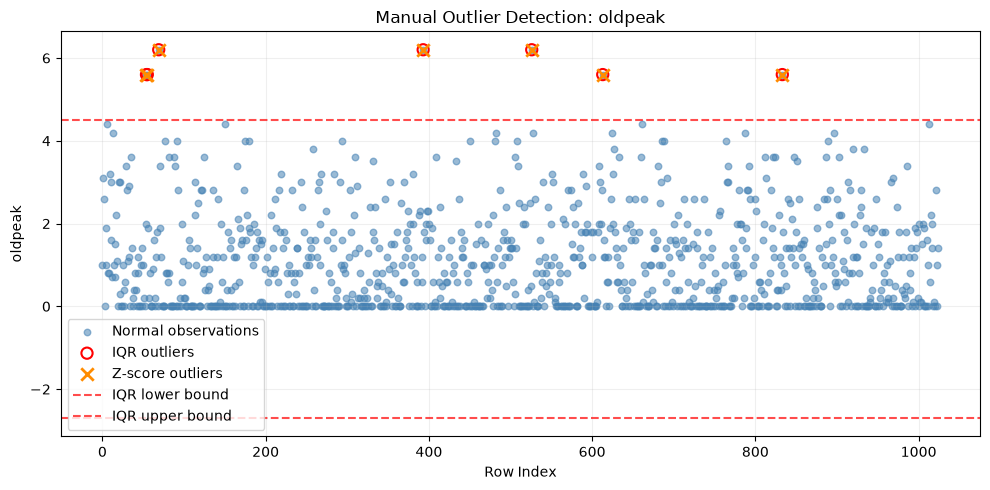

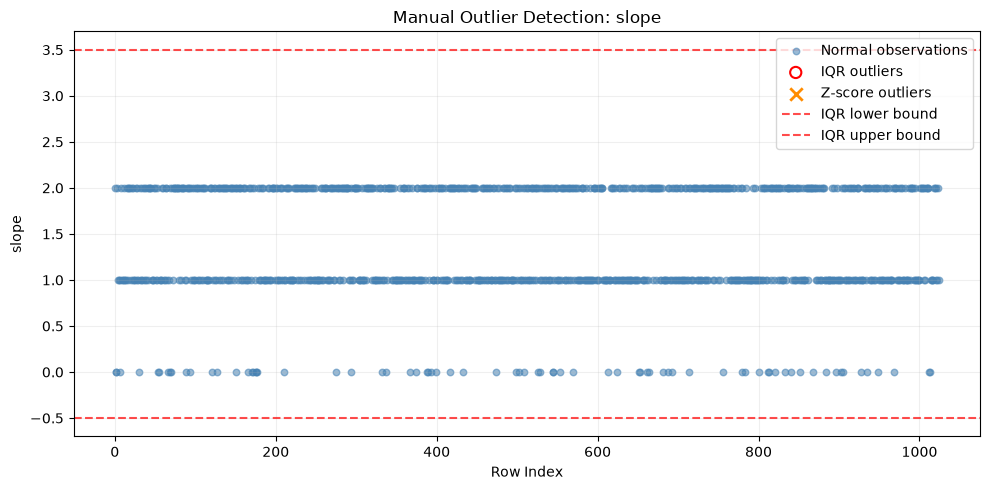

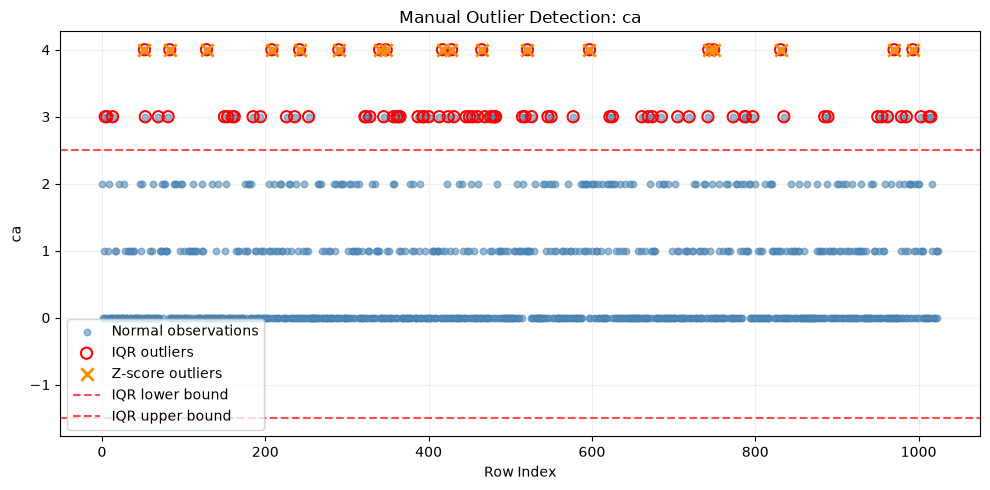

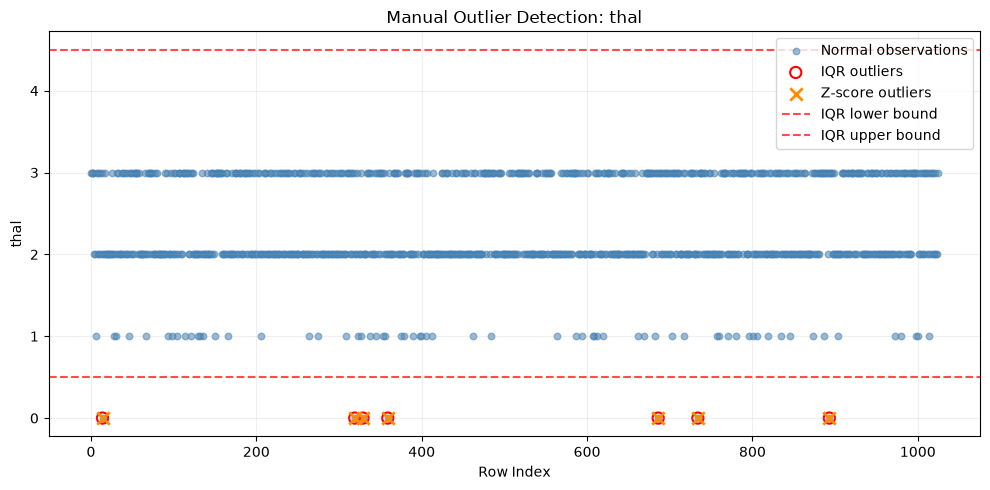

In [6]:
for col in feature_columns:
    values = [
        (index, float(value))
        for index, value in enumerate(df[col])
        if pd.notna(value)
    ]

    if not values:
        continue

    result = outlier_results[col]

    indices = [item[0] for item in values]
    measurements = [item[1] for item in values]

    iqr_indices = [index for index, value in result["iqr_outliers"]]
    iqr_values = [value for index, value in result["iqr_outliers"]]

    z_indices = [
        index for index, value, score in result["zscore_outliers"]
    ]
    z_values = [
        value for index, value, score in result["zscore_outliers"]
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # All observations
    ax.scatter(
        indices,
        measurements,
        s=22,
        color="steelblue",
        alpha=0.55,
        label="Normal observations"
    )

    # IQR outliers
    ax.scatter(
        iqr_indices,
        iqr_values,
        s=65,
        marker="o",
        facecolors="none",
        edgecolors="red",
        linewidths=1.5,
        label="IQR outliers"
    )

    # Z-score outliers
    ax.scatter(
        z_indices,
        z_values,
        s=80,
        marker="x",
        color="darkorange",
        linewidths=2,
        label="Z-score outliers"
    )

    ax.axhline(
        result["lower_bound"],
        color="red",
        linestyle="--",
        alpha=0.7,
        label="IQR lower bound"
    )

    ax.axhline(
        result["upper_bound"],
        color="red",
        linestyle="--",
        alpha=0.7,
        label="IQR upper bound"
    )

    ax.set_title(f"Manual Outlier Detection: {col}")
    ax.set_xlabel("Row Index")
    ax.set_ylabel(col)
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

In [7]:
summary_rows = []

for col, result in outlier_results.items():
    summary_rows.append({
        "Feature": col,
        "IQR Outliers": len(result["iqr_outliers"]),
        "Z-score Outliers": len(result["zscore_outliers"]),
        "Mean": round(result["mean"], 2),
        "Std Dev": round(result["std"], 2)
    })

summary_df = pd.DataFrame(summary_rows)

print(summary_df.to_string(index=False))

 Feature  IQR Outliers  Z-score Outliers   Mean  Std Dev
     age             0                 0  54.43     9.07
     sex             0                 0   0.70     0.46
      cp             0                 0   0.94     1.03
trestbps            30                 7 131.61    17.51
    chol            16                13 246.00    51.57
     fbs           153                 0   0.15     0.36
 restecg             0                 0   0.53     0.53
 thalach             4                 4 149.11    22.99
   exang             0                 0   0.34     0.47
 oldpeak             7                 7   1.07     1.17
   slope             0                 0   1.39     0.62
      ca            87                18   0.75     1.03
    thal             7                 7   2.32     0.62


## Conclusion

In this task, numerical features were analyzed using two outlier detection
methods: the Interquartile Range (IQR) method and the Z-score method.
Quartiles, mean, and population standard deviation were calculated manually.
Custom scatter plots were used to visualize the detected outliers.

The two methods may identify different observations because they use
different statistical criteria. A detected outlier is not automatically
an error and should be investigated before removing or modifying it.